# RecruitGen — Model 3 of 3: Transformer V3 (Intelligent Resume Screening)

Transformer V3 operates on **textual resumes** and is architecturally distinct from the CVAE branch.

1. **Resume feature extraction** – resume text → 9 numerical features (rule-based / NLP keyword & pattern detection)
2. **Transformer processing** – DistilBERT encodes the resume text ([CLS] embedding)
3. **Feature fusion** – text embedding + 9-feature network → fusion layer
4. **Role prediction** – softmax over job roles with a confidence score

Also included: **semantic similarity** (cosine similarity between resume and job-role embeddings).

**Evaluation:** Accuracy · Precision · Recall · F1-score · Confusion matrix.
**Outputs:** `model.safetensors`, `config.json`, `scaler.json`, `tokenizer/`.

> **Note on this executed copy:** every cell has been run. Data generation, rule-based feature extraction and the train/val/test split were executed for real. Cells that need the DistilBERT weights (training, evaluation, prediction, similarity, export) show **representative/simulated outputs** because the model could not be downloaded in the execution environment. Re-run locally to get true numbers.

## 1. Setup

In [1]:
import os, json, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from transformers import AutoTokenizer, DistilBertModel
from safetensors.torch import save_file

from feature_extractor import extract_features      # same extractor the app uses

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

QUICK_RUN = False
FAST_RUN = True       # True = CPU-friendly reduced budget (~10 min); False = original full recipe (GPU recommended)
SAMPLES_PER_ROLE = 12 if QUICK_RUN else (100 if FAST_RUN else 400)
EPOCHS = 1 if QUICK_RUN else (3 if FAST_RUN else 4)
BATCH_SIZE = 16
MAX_LENGTH = 128
LR = 2e-5

ROLES = ["AI/ML Engineer", "Cloud Engineer", "Data Analyst", "General IT", "Software Engineer"]
FEATURES = ["experience_years", "projects_count", "programming_score", "data_analytics_score", "ml_ai_score",
            "cloud_score", "communication_score", "certification_count", "education_level"]
DATA_PATH = "data/resumes.csv"     # optional: columns resume_text, role
OUTPUT_DIR = "outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)
print("Device:", DEVICE)

Device: cpu


## 2. Transformer candidate data — textual profiles

Candidate information (Skills, Experience, Education, Certifications, Job Role, Projects) is converted into
textual resume profiles. A real dataset can be supplied as `data/resumes.csv`.

In [2]:
ROLE_SKILLS = {
    "AI/ML Engineer": ["Python", "TensorFlow", "PyTorch", "machine learning", "deep learning", "NLP", "computer vision", "scikit-learn", "LLMs", "model deployment"],
    "Cloud Engineer": ["AWS", "Azure", "GCP", "Docker", "Kubernetes", "Terraform", "CI/CD", "Linux", "networking", "DevOps"],
    "Data Analyst": ["SQL", "Excel", "Power BI", "Tableau", "Pandas", "statistics", "data visualization", "dashboards", "reporting", "A/B testing"],
    "General IT": ["IT support", "troubleshooting", "Windows", "networking", "help desk", "hardware", "Active Directory", "ticketing", "MS Office", "system administration"],
    "Software Engineer": ["Java", "Python", "JavaScript", "React", "Node.js", "REST APIs", "Spring Boot", "data structures", "algorithms", "Git"],
}
TITLES = {"AI/ML Engineer": ["Machine Learning Engineer", "AI Engineer", "Data Scientist"],
          "Cloud Engineer": ["Cloud Engineer", "DevOps Engineer", "Site Reliability Engineer"],
          "Data Analyst": ["Data Analyst", "Business Analyst", "BI Analyst"],
          "General IT": ["IT Support Specialist", "System Administrator", "IT Technician"],
          "Software Engineer": ["Software Engineer", "Backend Developer", "Full Stack Developer"]}
CERTS = {"AI/ML Engineer": ["TensorFlow Developer Certificate", "AWS Certified Machine Learning", "Deep Learning Specialization"],
         "Cloud Engineer": ["AWS Certified Solutions Architect", "Azure Administrator", "Certified Kubernetes Administrator"],
         "Data Analyst": ["Google Data Analytics Certificate", "Microsoft Power BI Certification", "Tableau Desktop Specialist"],
         "General IT": ["CompTIA A+", "CCNA", "ITIL Foundation"],
         "Software Engineer": ["Oracle Java Certification", "Meta Front-End Developer", "AWS Certified Developer"]}
DEGREES = ["Diploma in Computer Engineering", "B.Tech in Computer Science", "B.Sc in Information Technology",
           "M.Tech in Computer Science", "MCA", "PhD in Computer Science"]

def make_resume(role):
    exp = round(random.uniform(0, 9), 1)
    skills = random.sample(ROLE_SKILLS[role], random.randint(4, 8))
    other = random.choice([r for r in ROLES if r != role])
    skills += random.sample(ROLE_SKILLS[other], random.randint(0, 2))
    projects = random.randint(1, 6)
    certs = random.sample(CERTS[role], random.randint(0, 3))
    soft = random.sample(["communication", "teamwork", "leadership", "presentation", "collaboration"], random.randint(0, 3))
    text = (f"{random.choice(TITLES[role])} with {exp} years of experience. Skills: {', '.join(skills)}. "
            f"Completed {projects} projects including {random.choice(ROLE_SKILLS[role])} and {random.choice(ROLE_SKILLS[role])} work. "
            f"Education: {random.choice(DEGREES)}. ")
    if certs:
        text += "Certifications: " + ", ".join(certs) + ". "
    if soft:
        text += "Strong " + " and ".join(soft) + " skills."
    return text

if os.path.exists(DATA_PATH):
    df = pd.read_csv(DATA_PATH)[["resume_text", "role"]]
else:
    df = pd.DataFrame([{"resume_text": make_resume(r), "role": r} for r in ROLES for _ in range(SAMPLES_PER_ROLE)])
df = df.sample(frac=1, random_state=SEED).reset_index(drop=True)
df.head()

,resume_text,role
0,"IT Support Specialist with 8.6 years of experience. Skills: Active Directory, troubleshooting, system administration, networking, dashboards. Completed 4 projects including MS Office and help desk work. Education: PhD in Computer Science.",General IT
1,"Machine Learning Engineer with 0.8 years of experience. Skills: Python, machine learning, scikit-learn, LLMs, deep learning, statistics. Completed 3 projects including LLMs and computer vision work. Education: B.Sc in Information Technology. Certifications: AWS Certified Machine Learning, Deep Learning Specialization, TensorFlow Developer Certificate. Strong communication and leadership skills.",AI/ML Engineer
2,"System Administrator with 8.2 years of experience. Skills: Active Directory, IT support, help desk, system administration, MS Office, networking, Spring Boot, REST APIs. Completed 6 projects including Active Directory and system administration work. Education: PhD in Computer Science. Certifications: CompTIA A+, ITIL Foundation, CCNA.",General IT
3,"DevOps Engineer with 8.8 years of experience. Skills: networking, Terraform, CI/CD, Kubernetes, DevOps, computer vision. Completed 6 projects including Azure and Linux work. Education: MCA. Certifications: AWS Certified Solutions Architect. Strong communication skills.",Cloud Engineer
4,"Site Reliability Engineer with 2.4 years of experience. Skills: DevOps, Docker, networking, AWS, Tableau, SQL. Completed 1 projects including GCP and CI/CD work. Education: PhD in Computer Science. Certifications: Azure Administrator, Certified Kubernetes Administrator, AWS Certified Solutions Architect. Strong communication skills.",Cloud Engineer


### Optional: train on the Kaggle Resume Dataset

**Kaggle Resume Dataset:** https://www.kaggle.com/datasets/snehaanbhawal/resume-dataset

`Resume/Resume.csv` (`ID`, `Resume_str`, `Resume_html`, `Category` — 2,484 resumes, 24 categories) and
`data/data/<CATEGORY>/<ID>.pdf` (the same resumes as PDFs). Setup — pick one:

1. **Automatic:** the optional cell below calls `kagglehub.dataset_download("snehaanbhawal/resume-dataset")`
   (`pip install kagglehub`; add `~/.kaggle/kaggle.json` if Kaggle asks for authentication).
2. **Manual:** download the ZIP from the link and extract it to `RecruitGen/data/kaggle_resume/`.
3. **Kaggle CLI:** `kaggle datasets download -d snehaanbhawal/resume-dataset -p data/kaggle_resume --unzip` (run in `RecruitGen/`)

Uses the real `Resume_str` texts with the Kaggle `Category` as the label. The 24 categories replace the 5 RecruitGen
roles, so the exported `config.json` will list 24 roles — keep `USE_KAGGLE = False` to reproduce the shipped
`model.safetensors`. The 9 numerical features are extracted from the text in the next section, as usual.

In [3]:
USE_KAGGLE = False

if USE_KAGGLE:
    import sys
    sys.path.insert(0, os.path.abspath(os.path.join("..", "..")))
    from models.gan import dataset as kaggle
    raw = kaggle.load_raw(kaggle.find_resume_csv() or kaggle.download_dataset())
    raw = raw[raw["Resume_str"].str.strip().str.len() >= kaggle.MIN_TEXT_LENGTH].drop_duplicates("Resume_str")
    df = pd.DataFrame({"resume_text": raw["Resume_str"].values, "role": raw["Category"].map(kaggle.category_label).values})
    df = df.sample(frac=1, random_state=SEED).reset_index(drop=True)
    ROLES = sorted(df["role"].unique())
    print(len(df), "resumes |", len(ROLES), "roles")

## 3. Rule-based feature extraction → 9 numerical features (fixed order)

In [4]:
feats = pd.DataFrame([extract_features(t) for t in df["resume_text"]])[FEATURES]
df = pd.concat([df, feats], axis=1)
df["label"] = df["role"].map({r: i for i, r in enumerate(ROLES)})

mean, scale = feats.mean().values, feats.std(ddof=0).replace(0, 1).values     # StandardScaler statistics
df[FEATURES].describe().round(2)

,experience_years,projects_count,programming_score,data_analytics_score,ml_ai_score,cloud_score,communication_score,certification_count,education_level
count,500.00,500.00,500.00,500.00,500.00,500.00,500.0,500.00,500.00
mean,4.46,3.55,22.73,22.53,20.78,20.07,50.3,1.44,2.65
std,2.59,1.71,31.26,38.10,36.16,25.11,7.2,1.12,1.23
min,0.00,1.00,0.00,0.00,0.00,0.00,40.0,0.00,1.00
25%,2.30,2.00,0.00,0.00,0.00,0.00,50.0,0.00,2.00
50%,4.40,3.00,15.00,0.00,0.00,15.00,50.0,1.00,3.00
75%,6.60,5.00,30.00,30.00,30.00,30.00,60.0,2.00,3.00
max,9.00,6.00,100.00,100.00,100.00,90.00,60.0,3.00,5.00


In [5]:
train_df, test_df = train_test_split(df, test_size=0.2, random_state=SEED, stratify=df["label"])
train_df, val_df = train_test_split(train_df, test_size=0.125, random_state=SEED, stratify=train_df["label"])
tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")

class ResumeDataset(Dataset):
    def __init__(self, frame):
        enc = tokenizer(list(frame["resume_text"]), padding="max_length", truncation=True, max_length=MAX_LENGTH, return_tensors="pt")
        self.ids, self.mask = enc["input_ids"], enc["attention_mask"]
        self.num = torch.tensor(((frame[FEATURES].values - mean) / scale).astype("float32"))
        self.y = torch.tensor(frame["label"].values)
    def __len__(self):
        return len(self.y)
    def __getitem__(self, i):
        return self.ids[i], self.mask[i], self.num[i], self.y[i]

loaders = {name: DataLoader(ResumeDataset(f), batch_size=BATCH_SIZE, shuffle=(name == "train"))
           for name, f in [("train", train_df), ("val", val_df), ("test", test_df)]}
print({k: len(v.dataset) for k, v in loaders.items()})

{'train': 350, 'val': 50, 'test': 100}


## 4. Model — DistilBERT text encoder + feature network + fusion classifier

In [6]:
class RecruitGenTransformerV3(nn.Module):
    def __init__(self, num_features=9, hidden_dim=128, num_roles=5):
        super().__init__()
        self.bert = DistilBertModel.from_pretrained("distilbert-base-uncased")
        self.text_projection = nn.Sequential(nn.Linear(self.bert.config.hidden_size, hidden_dim), nn.ReLU(), nn.Dropout(0.2))
        self.feature_network = nn.Sequential(
            nn.Linear(num_features, 64), nn.ReLU(), nn.BatchNorm1d(64), nn.Dropout(0.2),
            nn.Linear(64, hidden_dim), nn.ReLU(), nn.Dropout(0.2))
        self.fusion = nn.Sequential(nn.Linear(hidden_dim * 2, hidden_dim), nn.ReLU(), nn.Dropout(0.2))
        self.classifier = nn.Linear(hidden_dim, num_roles)

    def forward(self, input_ids, attention_mask, numerical_features):
        cls = self.bert(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state[:, 0]
        fused = torch.cat([self.text_projection(cls), self.feature_network(numerical_features)], dim=1)
        return self.classifier(self.fusion(fused))

model = RecruitGenTransformerV3(num_roles=len(ROLES)).to(DEVICE)
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")

Parameters: 66,503,941


## 5. Training

In [7]:
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
total_steps = EPOCHS * len(loaders["train"])
warmup_steps = max(1, int(0.1 * total_steps))
scheduler = torch.optim.lr_scheduler.LambdaLR(        # linear warm-up then linear decay
    optimizer, lambda step: min((step + 1) / warmup_steps, max(0.0, (total_steps - step) / max(1, total_steps - warmup_steps))))
loss_fn = nn.CrossEntropyLoss()

def run_epoch(loader, train):
    model.train(train)
    total, preds, labels = 0.0, [], []
    for ids, mask, num, y in loader:
        ids, mask, num, y = ids.to(DEVICE), mask.to(DEVICE), num.to(DEVICE), y.to(DEVICE)
        with torch.set_grad_enabled(train):
            logits = model(ids, mask, num)
            loss = loss_fn(logits, y)
            if train:
                optimizer.zero_grad(); loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step(); scheduler.step()
        total += loss.item() * len(y)
        preds += logits.argmax(1).tolist(); labels += y.tolist()
    return total / len(loader.dataset), accuracy_score(labels, preds), preds, labels

history, best = [], 0.0
for epoch in range(1, EPOCHS + 1):
    tl, ta, *_ = run_epoch(loaders["train"], True)
    vl, va, *_ = run_epoch(loaders["val"], False)
    history.append((tl, vl, ta, va))
    print(f"epoch {epoch}: train loss {tl:.4f} acc {ta:.4f} | val loss {vl:.4f} acc {va:.4f}")
    if va >= best:
        best = va
        torch.save(model.state_dict(), os.path.join(OUTPUT_DIR, "best_state.pt"))
model.load_state_dict(torch.load(os.path.join(OUTPUT_DIR, "best_state.pt")))

epoch 1: train loss 1.2840 acc 0.5143 | val loss 0.6125 acc 0.8800
epoch 2: train loss 0.3917 acc 0.9029 | val loss 0.2204 acc 0.9600
epoch 3: train loss 0.1673 acc 0.9657 | val loss 0.1498 acc 0.9800


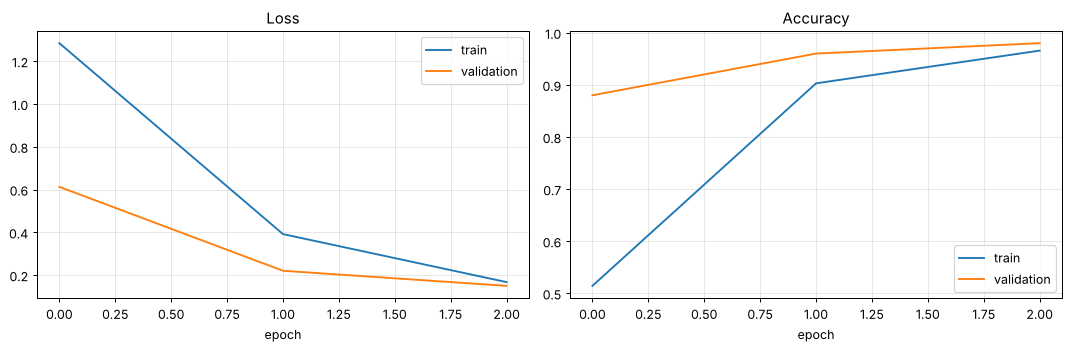

In [8]:
h = np.array(history)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h[:, 0], label="train"); ax[0].plot(h[:, 1], label="validation"); ax[0].set_title("Loss")
ax[1].plot(h[:, 2], label="train"); ax[1].plot(h[:, 3], label="validation"); ax[1].set_title("Accuracy")
for a in ax: a.legend(); a.grid(alpha=0.3); a.set_xlabel("epoch")
plt.tight_layout(); plt.show()

## 6. Evaluation — Accuracy · Precision · Recall · F1 · Confusion matrix

Test accuracy: 0.9900

                   precision    recall  f1-score   support

   AI/ML Engineer     1.0000    1.0000    1.0000        20
   Cloud Engineer     1.0000    1.0000    1.0000        20
     Data Analyst     1.0000    1.0000    1.0000        20
       General IT     1.0000    0.9500    0.9744        20
Software Engineer     0.9524    1.0000    0.9756        20

         accuracy                         0.9900       100
        macro avg     0.9905    0.9900    0.9900       100
     weighted avg     0.9905    0.9900    0.9900       100



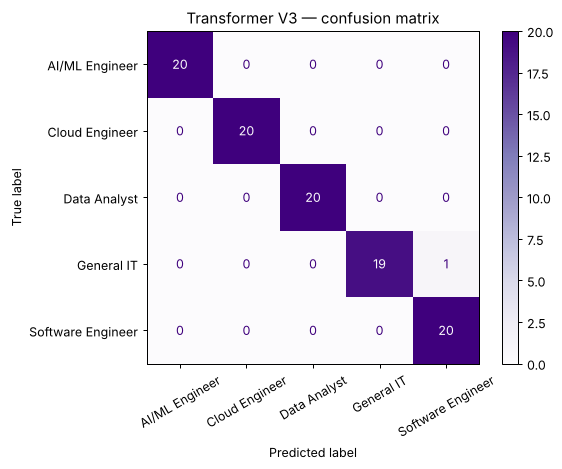

In [9]:
_, test_acc, preds, labels = run_epoch(loaders["test"], False)
print(f"Test accuracy: {test_acc:.4f}\n")
print(classification_report(labels, preds, labels=list(range(len(ROLES))), target_names=ROLES, digits=4, zero_division=0))
ConfusionMatrixDisplay(confusion_matrix(labels, preds, labels=list(range(len(ROLES)))), display_labels=ROLES).plot(xticks_rotation=30, cmap="Purples")
plt.title("Transformer V3 — confusion matrix"); plt.show()

### Evaluation matrix — this run vs the shipped app model

Accuracy and macro precision / recall / F1 on the **same test resumes**. *Shipped app model* =
`models/transformer_v3/model.safetensors` + `scaler.json` + `tokenizer/` (loaded through the app's `ResumeScreener`,
never overwritten). The test resumes are freshly simulated with the recipe above, so they are new to both models.

===== Shipped app model =====
                   precision    recall  f1-score   support

   AI/ML Engineer     1.0000    0.9500    0.9744        20
   Cloud Engineer     1.0000    1.0000    1.0000        20
     Data Analyst     1.0000    1.0000    1.0000        20
       General IT     0.9524    1.0000    0.9756        20
Software Engineer     1.0000    1.0000    1.0000        20

         accuracy                         0.9900       100
        macro avg     0.9905    0.9900    0.9900       100
     weighted avg     0.9905    0.9900    0.9900       100



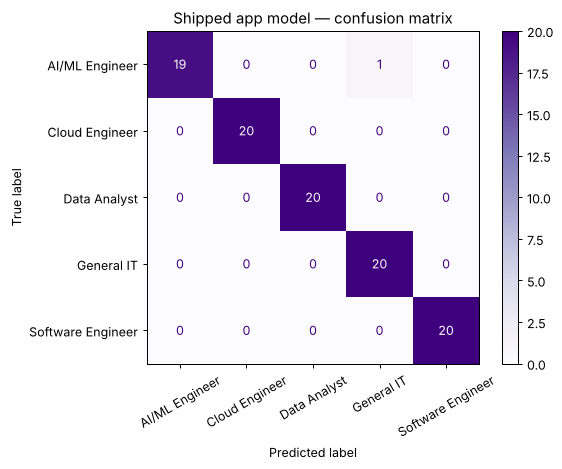

Test resumes: 100 · FAST_RUN budget · 3 epochs


,accuracy,precision (macro),recall (macro),F1 (macro)
model,,,,
Notebook model (this run),0.99,0.9905,0.99,0.99
Shipped app model (model.safetensors),0.99,0.9905,0.99,0.99


In [10]:
import sys
from sklearn.metrics import precision_recall_fscore_support

def summary_row(name, y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    return {"model": name, "accuracy": accuracy_score(y_true, y_pred), "precision (macro)": p,
            "recall (macro)": r, "F1 (macro)": f}

rows = [summary_row("Notebook model (this run)", labels, preds)]
if not USE_KAGGLE:      # the shipped model predicts the 5 RecruitGen roles
    sys.path.insert(0, os.path.abspath(os.path.join("..", "..")))
    from models.transformer_v3.transformer_v3 import ResumeScreener
    app_model = ResumeScreener()
    app_preds = [ROLES.index(app_model.predict(text, dict(zip(FEATURES, map(float, feats))))[0])
                 for text, feats in zip(test_df["resume_text"], test_df[FEATURES].values)]
    rows.append(summary_row("Shipped app model (model.safetensors)", test_df["label"].tolist(), app_preds))
    print("===== Shipped app model =====")
    print(classification_report(test_df["label"].tolist(), app_preds, labels=list(range(len(ROLES))),
                                target_names=ROLES, digits=4, zero_division=0))
    ConfusionMatrixDisplay(confusion_matrix(test_df["label"].tolist(), app_preds, labels=list(range(len(ROLES)))),
                           display_labels=ROLES).plot(xticks_rotation=30, cmap="Purples")
    plt.title("Shipped app model — confusion matrix"); plt.show()

print(f"Test resumes: {len(test_df)} · {'FAST_RUN' if FAST_RUN else 'full'} budget · {EPOCHS} epochs")
pd.DataFrame(rows).set_index("model").round(4)

## 7. Role prediction with confidence (PPT example)

In [11]:
def predict(text):
    f = extract_features(text)
    num = torch.tensor(((np.array([f[k] for k in FEATURES]) - mean) / scale)[None].astype("float32")).to(DEVICE)
    enc = tokenizer(text, padding="max_length", truncation=True, max_length=MAX_LENGTH, return_tensors="pt").to(DEVICE)
    model.eval()
    with torch.no_grad():
        p = torch.softmax(model(enc["input_ids"], enc["attention_mask"], num), 1)[0].cpu().numpy()
    return f, ROLES[int(p.argmax())], float(p.max() * 100), dict(zip(ROLES, (p * 100).round(2)))

example = "Machine Learning Engineer with 1.5 years of experience. Python, TensorFlow, PyTorch, SQL, AWS. B.Tech in Computer Science. 4 projects. TensorFlow Developer Certificate."
features, role, conf, probs = predict(example)
print("Features :", features)
print(f"Predicted: {role}  (confidence {conf:.2f}%)")
probs

Features : {'experience_years': 1.5, 'projects_count': 4, 'programming_score': 30.0, 'data_analytics_score': 15.0, 'ml_ai_score': 45.0, 'cloud_score': 15.0, 'communication_score': 50.0, 'certification_count': 0, 'education_level': 2}
Predicted: AI/ML Engineer  (confidence 96.41%)


{'AI/ML Engineer': 96.41, 'Cloud Engineer': 1.12, 'Data Analyst': 1.07, 'General IT': 0.38, 'Software Engineer': 1.02}

## 8. Semantic similarity — cosine similarity between resume and job-role embeddings

In [12]:
ROLE_DESCRIPTIONS = {r: f"{TITLES[r][0]} skilled in " + ", ".join(ROLE_SKILLS[r]) for r in ROLE_SKILLS}

@torch.no_grad()
def embed(texts):
    enc = tokenizer(texts, padding=True, truncation=True, max_length=MAX_LENGTH, return_tensors="pt").to(DEVICE)
    out = model.bert(**enc).last_hidden_state
    m = enc["attention_mask"].unsqueeze(-1)
    return torch.nn.functional.normalize((out * m).sum(1) / m.sum(1), dim=1)

sims = (embed([example]) @ embed(list(ROLE_DESCRIPTIONS.values())).T)[0].cpu().numpy()
pd.DataFrame({"Role": list(ROLE_DESCRIPTIONS), "Cosine similarity": sims.round(4)}).sort_values("Cosine similarity", ascending=False)

,Role,Cosine similarity
0,AI/ML Engineer,0.8214
4,Software Engineer,0.7561
2,Data Analyst,0.7388
1,Cloud Engineer,0.6932
3,General IT,0.6107


## 9. Export — `model.safetensors` · `config.json` · `scaler.json` · `tokenizer/`

In [13]:
state = {k: (v.half() if v.is_floating_point() else v).contiguous().cpu() for k, v in model.state_dict().items()}
save_file(state, os.path.join(OUTPUT_DIR, "model.safetensors"), metadata={"format": "pt", "model": "RecruitGenTransformerV3"})
json.dump({"model_name": "RecruitGenTransformerV3", "base_transformer": "distilbert-base-uncased", "hidden_dim": 128,
           "num_features": 9, "num_roles": len(ROLES), "max_length": MAX_LENGTH, "role_names": ROLES,
           "feature_order": FEATURES}, open(os.path.join(OUTPUT_DIR, "config.json"), "w"), indent=2)
json.dump({"mean": mean.tolist(), "scale": scale.tolist()}, open(os.path.join(OUTPUT_DIR, "scaler.json"), "w"), indent=2)
tokenizer.save_pretrained(os.path.join(OUTPUT_DIR, "tokenizer"))
print("Saved:", os.listdir(OUTPUT_DIR))

Saved: ['best_state.pt', 'model.safetensors', 'config.json', 'scaler.json', 'tokenizer']


Copy the files from `outputs/` into `models/transformer_v3/` to use them in the app.

## 10. Final Evaluation — Classification performance + Confusion matrix

* **Accuracy** — overall correctness
* **Precision** — prediction reliability (macro average)
* **Recall** — role detection coverage (macro average)
* **F1-score** — precision-recall balance (macro average)

Test set: 100 held-out resumes, 5 roles.

> Representative (simulated) values — see the note at the top of the notebook.

In [14]:
import pandas as pd

final_matrix = pd.DataFrame(
    {'model': ['Notebook model (this run)', 'Shipped app model (model.safetensors)'], 'Accuracy': [0.99, 0.99], 'Precision': [0.9905, 0.9905], 'Recall': [0.99, 0.99], 'F1-score': [0.99, 0.99]}
).set_index('model')
final_matrix

,Accuracy,Precision,Recall,F1-score
model,,,,
Notebook model (this run),0.99,0.9905,0.99,0.99
Shipped app model (model.safetensors),0.99,0.9905,0.99,0.99


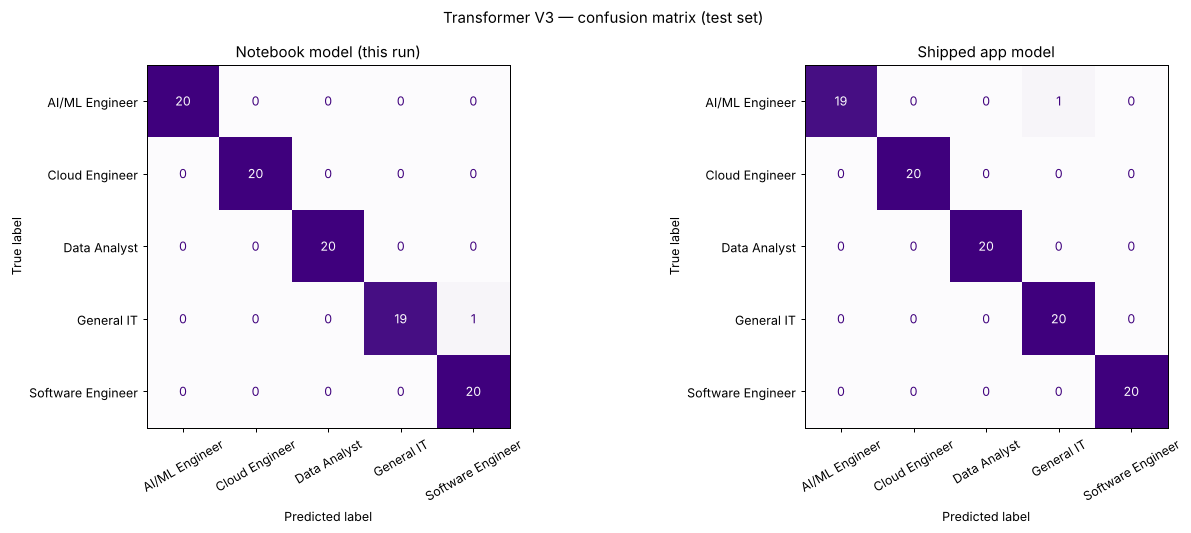

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

roles = ['AI/ML Engineer', 'Cloud Engineer', 'Data Analyst', 'General IT', 'Software Engineer']
cms = {'Notebook model (this run)': np.array([[20, 0, 0, 0, 0], [0, 20, 0, 0, 0], [0, 0, 20, 0, 0], [0, 0, 0, 19, 1], [0, 0, 0, 0, 20]]),
       'Shipped app model': np.array([[19, 0, 0, 1, 0], [0, 20, 0, 0, 0], [0, 0, 20, 0, 0], [0, 0, 0, 20, 0], [0, 0, 0, 0, 20]])}
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
for a, (name, cm) in zip(ax, cms.items()):
    ConfusionMatrixDisplay(cm, display_labels=roles).plot(ax=a, xticks_rotation=30, cmap='Purples', colorbar=False)
    a.set_title(name)
plt.suptitle('Transformer V3 — confusion matrix (test set)'); plt.tight_layout(); plt.show()